In [9]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

In [27]:
df = pl.read_csv("missiles.csv")
df = df.unique()
df = df.sort("t")
ids = df.unique(subset=["id",]).sort("id")
ids

t,id,type,x,y,z
i64,i64,str,f64,f64,f64
346,3000,"""missile""",-85.904,71.205,249.76
346,3013,"""target""",-200.01,-22.9,120.0
406,3890,"""target""",-194.38,-22.9,120.0
407,3899,"""target""",-194.29,-22.9,120.0
425,4484,"""target""",-192.6,-22.9,120.0
…,…,…,…,…,…
2242,38026,"""target""",-22.25,-22.9,120.0
2245,38039,"""missile""",-21.97,-22.9,120.0
2261,38336,"""missile""",-20.47,-22.9,120.0


In [ ]:
# plt.plot(m1["steps"], m1["x"], label="Missile")
# plt.show()
# plt.plot(m1["steps"], m1["y"], label="Missile")
# plt.show()
# plt.plot(m1["steps"], m1["z"], label="Missile")
# plt.show()
# plt.plot(t1["steps"], t1["x"], label="Target")
# plt.show()
# plt.plot(t1["steps"], t1["y"], label="Target")
# plt.show()
# plt.plot(t1["steps"], t1["z"], label="Target")
# plt.show()

4484

In [ ]:
# for i in range(50):
#     pid = ids["id"][i]
#     m1 = df.filter((pl.col("id") == pid) & (pl.col("type") == "missile")).select(["t", "x", "y", "z"])
#     t1 = df.filter((pl.col("id") == pid) & (pl.col("type") == "target")).select(["t", "x", "y", "z"])

#     plt.plot(m1["x"], m1["y"], label="Missile")
#     plt.plot(t1["x"], t1["y"], label="Target")
#     plt.title(f"ID {i}: {pid}")

#     plt.legend()
#     plt.show()

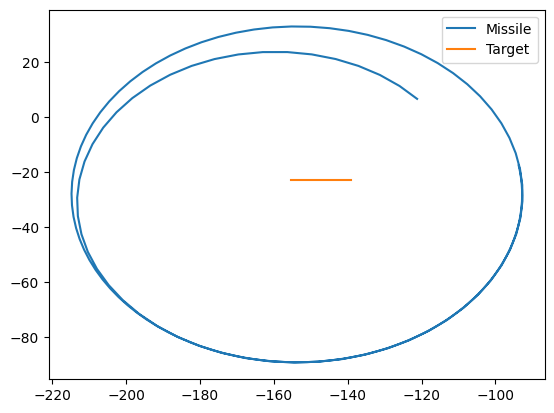

In [82]:
pid = ids["id"][25]
m1 = df.filter((pl.col("id") == pid) & (pl.col("type") == "missile")).select(["t", "x", "y", "z"])
t1 = df.filter((pl.col("id") == pid) & (pl.col("type") == "target")).select(["t", "x", "y", "z"])
m1 = m1.slice(1)
t1 = t1.slice(1)

plt.plot(m1["x"], m1["y"], label="Missile")
plt.plot(t1["x"], t1["y"], label="Target")
plt.legend()
plt.show()

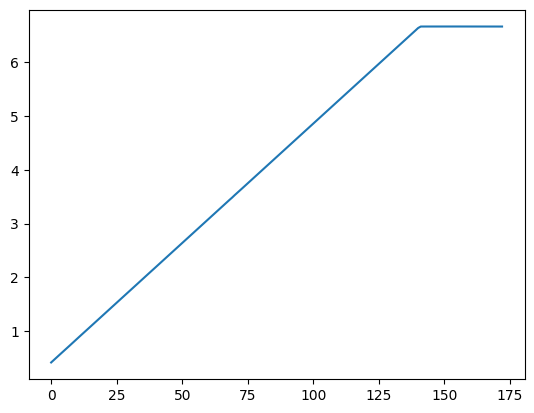

In [102]:
# generate velocity from m1["x"] and m1["y"]
v_history = np.sqrt(np.diff(m1["x"])**2 + np.diff(m1["y"])**2)
plt.plot(v_history, label="Velocity")
plt.show()

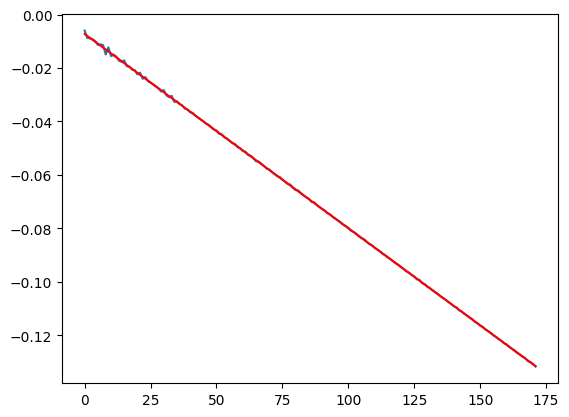

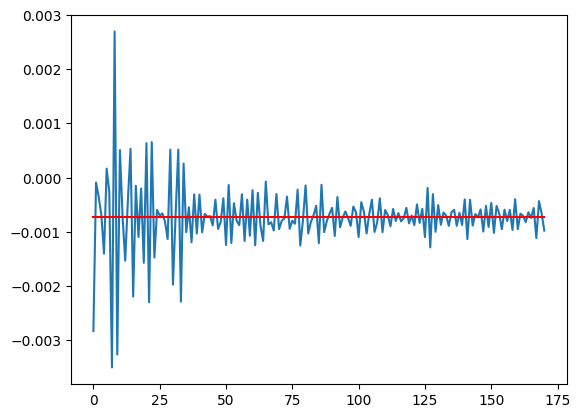

In [103]:
DEGREE = np.pi / 180
DEGREE_S = np.pi / 180 / 60
DEGREE_S2 = np.pi / 180 / 60 / 60

# plt.plot(np.arctan2(m1["y"].to_numpy(), m1["x"].to_numpy()))
angle_history = np.unwrap(np.arctan2(np.diff(m1["y"]), np.diff(m1["x"])))
angle_v_history = np.diff(angle_history)
angle_a_history = np.diff(angle_v_history)
plt.plot(angle_v_history)
plt.plot(-25 * DEGREE_S - np.arange(len(angle_v_history)) * 150 * DEGREE_S2, color="red")
plt.show()
plt.plot(angle_a_history)
plt.plot(-150 * DEGREE_S2 * np.ones(len(angle_a_history)), color="red")
plt.show()


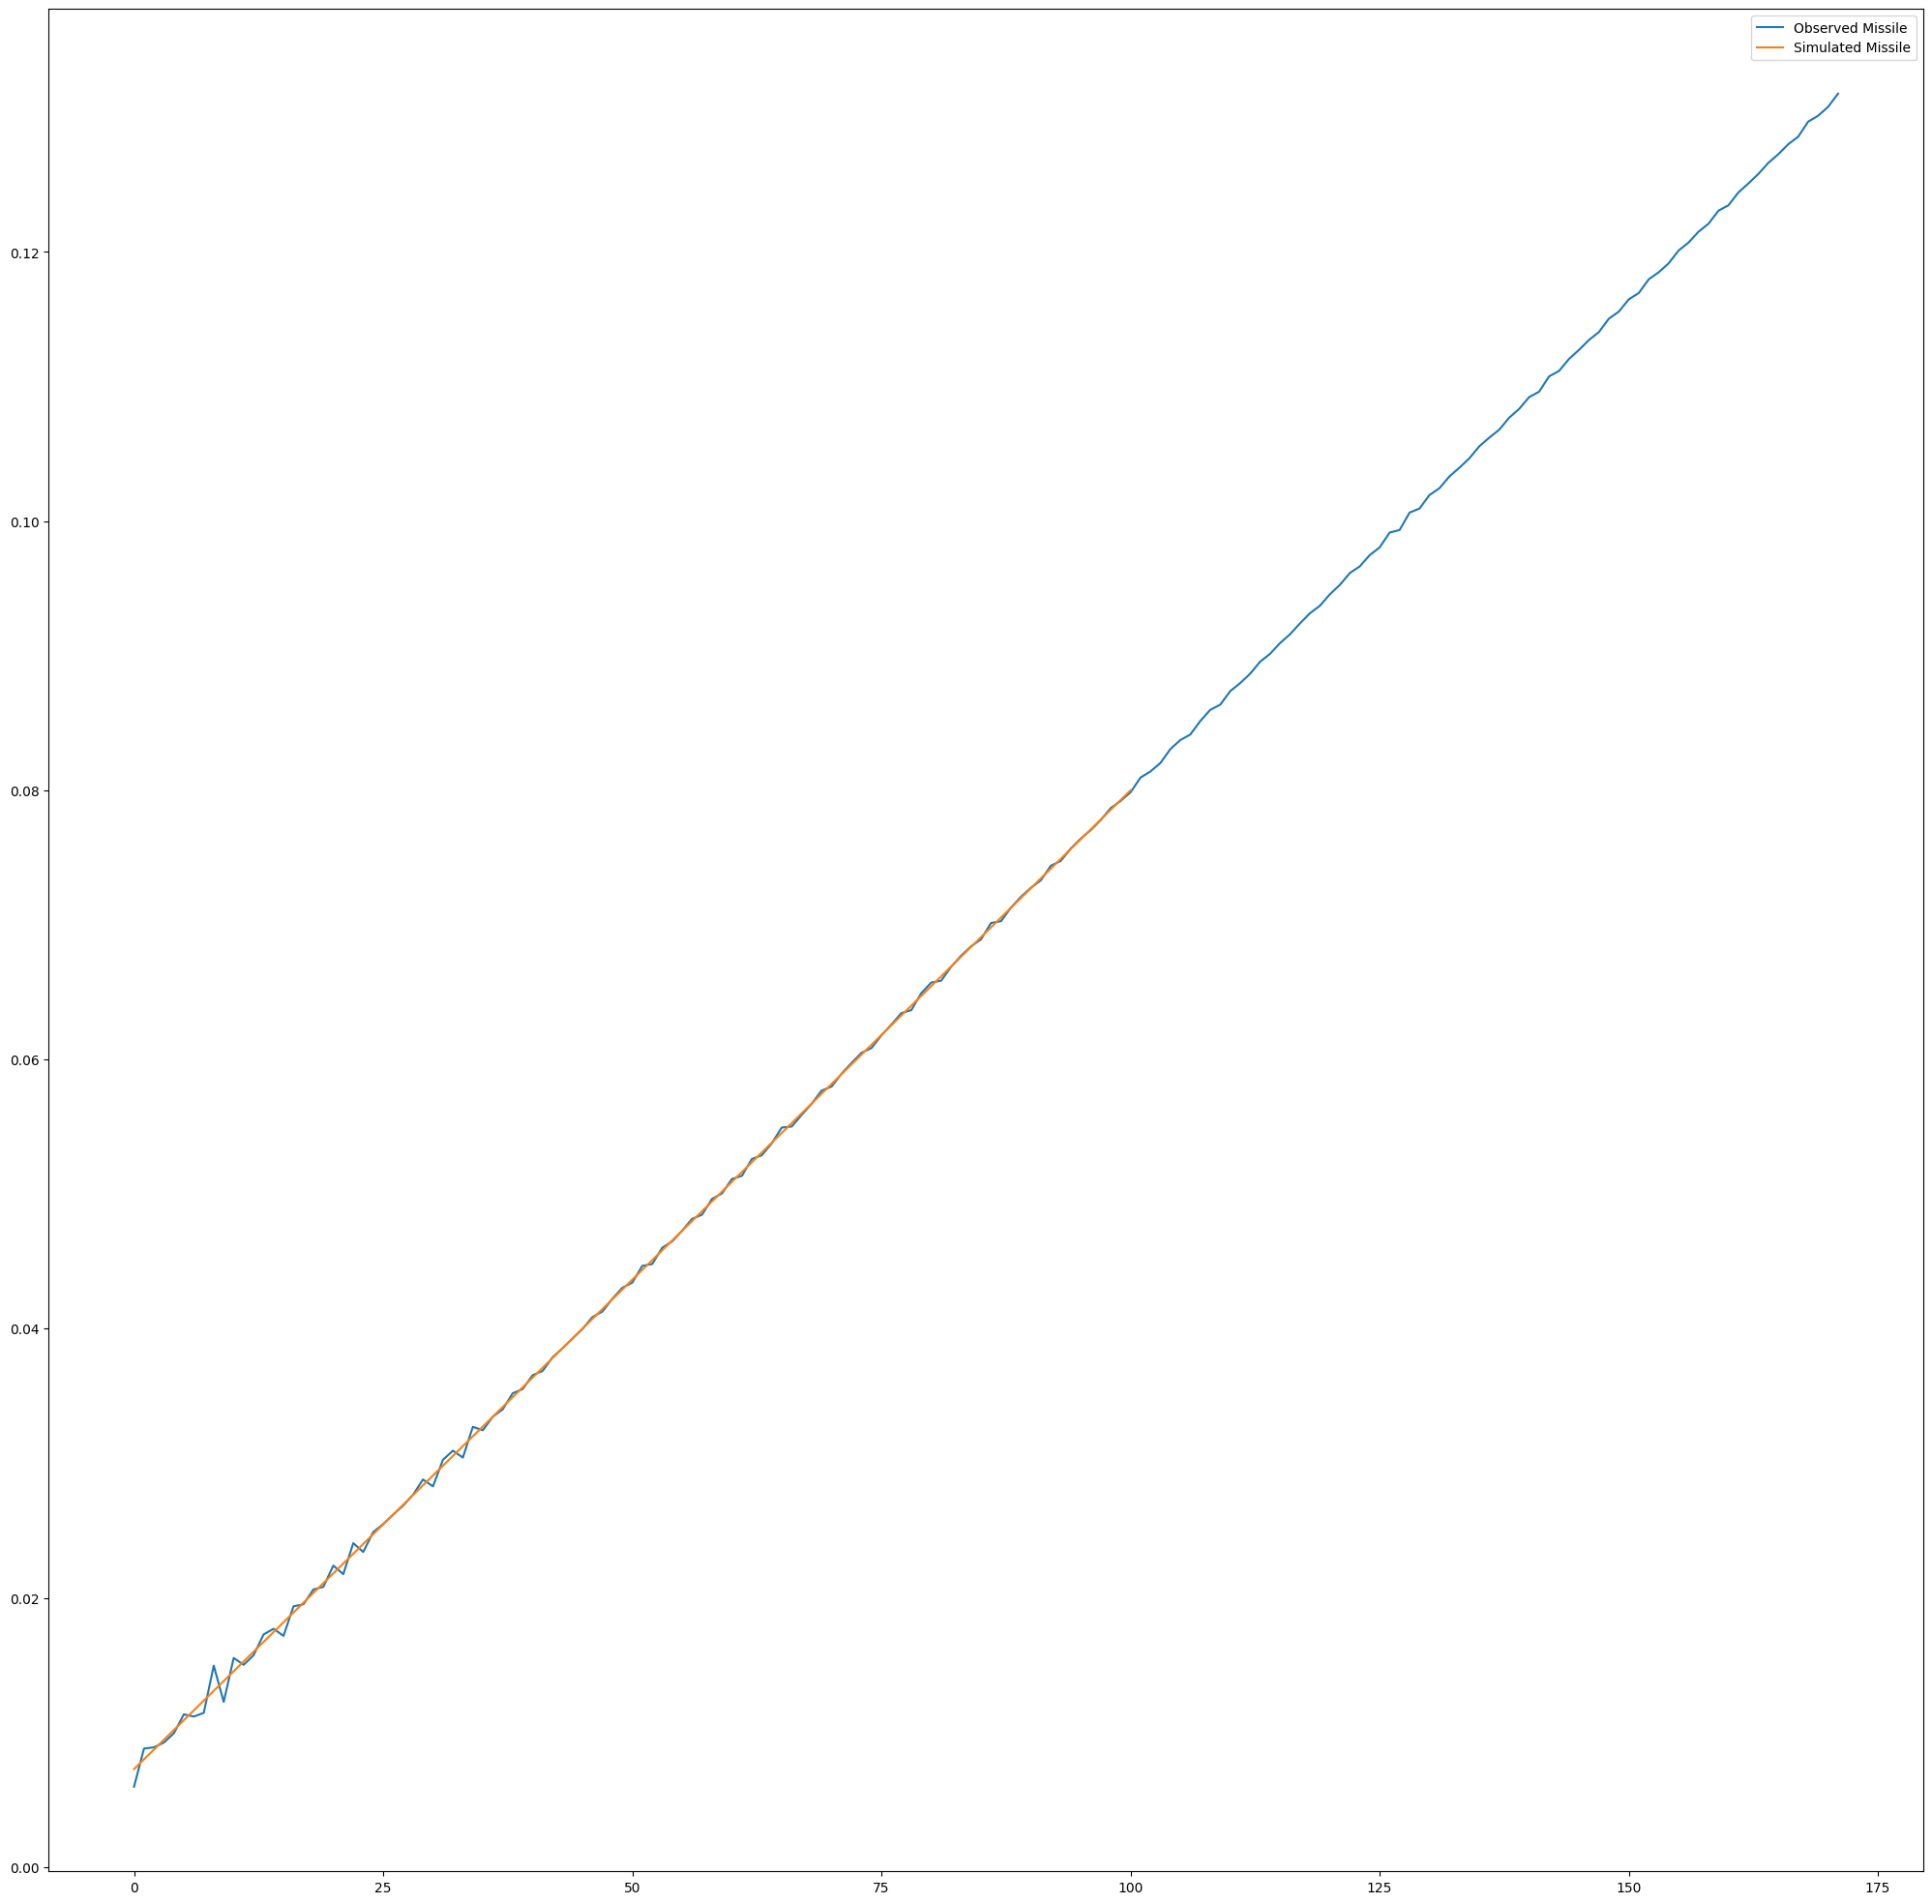

In [153]:
plt.figure(figsize=(25, 25))
m1 = m1.head(100)

initial_angle = np.arctan2(m1["y"][1] - m1["y"][0], m1["x"][1] - m1["x"][0])
angle = initial_angle + 1 * DEGREE

x = m1["x"][0]
y = m1["y"][0]
v = 25 / 60
angle_v = 25 * DEGREE_S

# history
x_sim = [x]
y_sim = [y]
v_sim = [v]
angle_v_sim = [angle_v]


for i in range(0, len(m1["x"])):
    angle_to_target = np.arctan2(t1["y"][i] - y, t1["x"][i] - x)
    diff = (angle - angle_to_target) % (2 * np.pi) - np.pi
    
    # update v and angle_v
    v += 160 / 60 / 60
    v = min(v, 400/60) # max speed
    angle_v += 150 * DEGREE_S2
    angle_v = min(angle_v, 500 * DEGREE_S) # max turn rate
    
    # update angle
    angle += np.sign(diff) * angle_v
    # update position
    x = x + np.cos(angle) * v
    y = y + np.sin(angle) * v
    
    # update history
    x_sim.append(x)
    y_sim.append(y)
    v_sim.append(v)
    angle_v_sim.append(angle_v)

# plt.plot(m1["x"], m1["y"], label="Observed Missile", marker="o", markersize=3, linestyle="None")
# plt.plot(x_sim, y_sim, label="Simulated Missile", marker="x", markersize=2, linestyle="None")
# plt.plot(v_history, label="Observed Missile")
# plt.plot(v_sim, label="Simulated Missile")
plt.plot(np.abs(angle_v_history), label="Observed Missile")
plt.plot(np.abs(angle_v_sim), label="Simulated Missile")

plt.legend()
plt.show()